### **Lab 1 - Exploratory Data Analysis (EDA) of Time Series**

Before fitting any model we need to *look* at the data. In this lab we explore three real time series, one after the other, and we do **not** fit any regression. We ask the questions every forecaster should ask first:

1. **CO$_2$ at Mauna Loa** (weekly, 1958–2001): missing values, resampling, trend, seasonality, rolling statistics, decomposition, autocorrelation.
2. **Sunspots** (yearly, 1700–2008): distribution, mean vs. median, skewness, transformations, outliers, cycles.
3. **Southern Oscillation Index and fish Recruitment** (monthly, 1950–1987): two series together, correlations, lagged relationships, and the danger of spurious correlation.

For each series we follow the same checklist:

| Step | Question |
|------|----------|
| Load & inspect | What is the frequency? Are there gaps, missing values, duplicates? |
| Plot | Is there a trend? A seasonal pattern? Sudden changes? |
| Summary statistics | Mean, median, quantiles, spread. Are they stable over time? |
| Distribution | Symmetric? Skewed? Heavy tails? Outliers? |
| Seasonality | Which months/periods are high or low? |
| Dependence | How strongly is today related to the past (ACF, lag plots)? |
| Stationarity | Do mean and variance stay constant? |

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import statsmodels.api as sm                      # datasets and statistical tools
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from scipy import stats

import astsa                                      # datasets from Shumway & Stoffer (pip install astsa)

import warnings                                   # keep the output readable
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=InterpolationWarning)

plt.rcParams['figure.figsize'] = (10, 4)
np.random.seed(42)                                # random seed for reproducibility

---
## **Part 1 - CO$_2$ at Mauna Loa**

The `co2` dataset in `statsmodels` contains weekly measurements of atmospheric CO$_2$ concentration (parts per million) at the Mauna Loa Observatory in Hawaii, from March 1958 to December 2001. It is one of the most famous time series in science (the *Keeling curve*).

### 1.1 Load and inspect

The first thing to check is the **structure** of the data: the index (is it really a date?), the frequency, the number of observations and whether anything is missing.

In [2]:
co2 = sm.datasets.co2.load_pandas().data       # a DataFrame with a DatetimeIndex
print(co2.head())
print()
print('Number of observations :', len(co2))
print('First / last date      :', co2.index.min().date(), '/', co2.index.max().date())
print('Inferred frequency     :', pd.infer_freq(co2.index))
print('Missing values         :', co2['co2'].isna().sum())
print('Duplicated dates       :', co2.index.duplicated().sum())

              co2
1958-03-29  316.1
1958-04-05  317.3
1958-04-12  317.6
1958-04-19  317.5
1958-04-26  316.4

Number of observations : 2284
First / last date      : 1958-03-29 / 2001-12-29
Inferred frequency     : W-SAT
Missing values         : 59
Duplicated dates       : 0


There are missing weeks. Where are they? Missing data that come in long blocks are more dangerous than isolated gaps.

2.6% of the weeks are missing
Number of gaps        : 22
Longest gap (weeks)   : 18


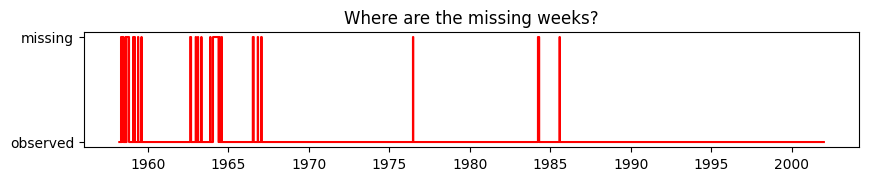

In [3]:
missing = co2['co2'].isna()
print(f'{missing.mean()*100:.1f}% of the weeks are missing')

# Length of each run of consecutive missing weeks
runs = (missing != missing.shift()).cumsum()
gap_lengths = missing.groupby(runs).sum()
gap_lengths = gap_lengths[gap_lengths > 0]
print('Number of gaps        :', len(gap_lengths))
print('Longest gap (weeks)   :', gap_lengths.max())

plt.figure(figsize=(10, 1.5))
plt.plot(co2.index, missing.astype(int), drawstyle='steps-mid', color='r')
plt.yticks([0, 1], ['observed', 'missing'])
plt.title('Where are the missing weeks?');

### 1.2 Resample to monthly values

Weekly data with gaps are awkward. A common first step is to **aggregate** to a regular, coarser frequency. Here we take the monthly mean, and fill the few remaining empty months by linear interpolation.

> **Question:** why could the *median* be a better monthly summary than the mean in some datasets? When would it not matter?

Empty months after resampling: 5


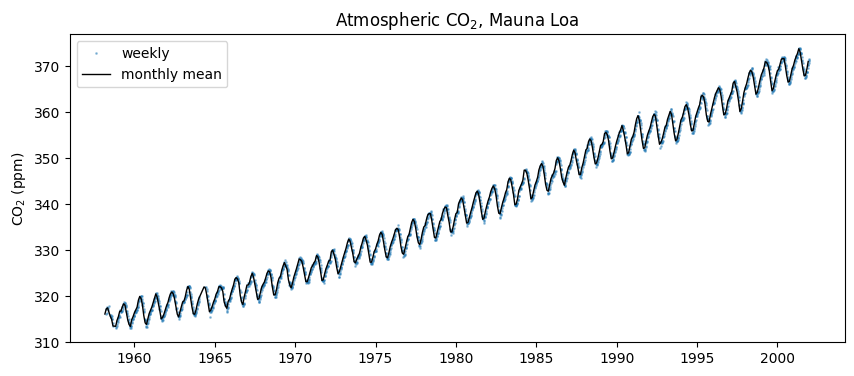

In [4]:
co2_m = co2['co2'].resample('MS').mean()          # 'MS' = month start
print('Empty months after resampling:', co2_m.isna().sum())
co2_m = co2_m.interpolate()                       # fill the few empty months

plt.plot(co2.index, co2['co2'], '.', ms=2, alpha=0.4, label='weekly')
plt.plot(co2_m.index, co2_m, lw=1, color='k', label='monthly mean')
plt.ylabel('CO$_2$ (ppm)')
plt.title('Atmospheric CO$_2$, Mauna Loa')
plt.legend();

### 1.3 Summary statistics

For a trending series, a single mean or median over the whole sample says very little: the "typical" value in 1960 is not the typical value in 2000. Compare the global statistics with the statistics **per decade**.

In [5]:
print(co2_m.describe().round(2))
print()
print('Median:', round(co2_m.median(), 2), '  Skewness:', round(co2_m.skew(), 3))

count    526.00
mean     339.62
std       17.12
min      313.40
25%      324.02
50%      337.91
75%      354.54
max      373.80
Name: co2, dtype: float64

Median: 337.91   Skewness: 0.25


In [6]:
by_decade = co2_m.groupby((co2_m.index.year // 10) * 10).agg(['mean', 'median', 'std', 'min', 'max'])
by_decade.index.name = 'decade'
print(by_decade.round(2))

          mean  median   std     min     max
decade                                      
1950    315.68  315.58  1.57  313.40  318.32
1960    320.24  320.23  2.95  313.84  327.28
1970    330.86  330.69  4.01  323.14  339.38
1980    345.29  345.05  4.98  335.88  355.60
1990    360.39  359.58  5.00  350.94  370.98
2000    370.11  370.06  1.97  366.54  373.80


### 1.4 Rolling statistics

**Rolling** (moving-window) statistics show how the level and the spread evolve. We use a 12-month window so that the seasonal cycle averages out.

> **Question:** the rolling mean keeps increasing. Is the rolling standard deviation also changing? What does that tell you about the variance of the series?

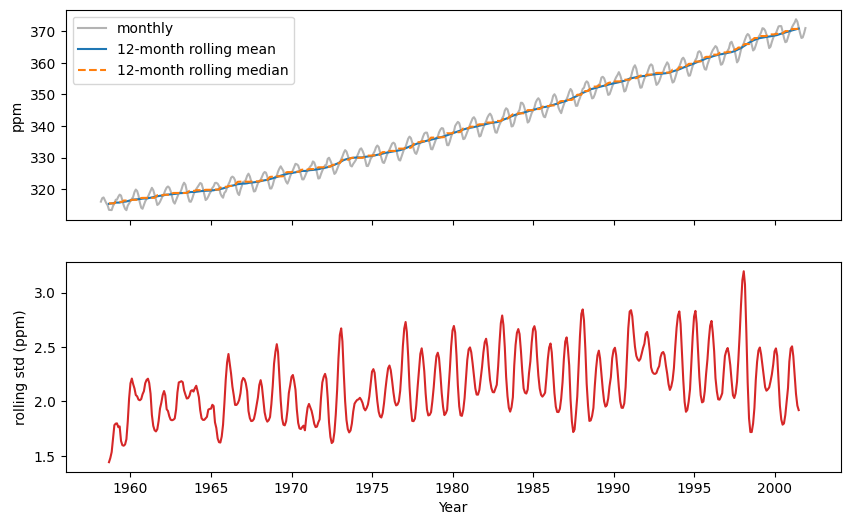

In [7]:
win = 12
roll_mean   = co2_m.rolling(win, center=True).mean()
roll_median = co2_m.rolling(win, center=True).median()
roll_std    = co2_m.rolling(win, center=True).std()

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(co2_m, color='0.7', label='monthly')
ax[0].plot(roll_mean, label='12-month rolling mean')
ax[0].plot(roll_median, '--', label='12-month rolling median')
ax[0].set_ylabel('ppm'); ax[0].legend()
ax[1].plot(roll_std, color='tab:red')
ax[1].set_ylabel('rolling std (ppm)')
ax[1].set_xlabel('Year');

### 1.5 Growth: year-over-year change

The **year-over-year difference** $x_t - x_{t-12}$ removes the seasonal pattern and shows how fast the level is rising.

Average annual increase, 1960s: 0.86 ppm/year
Average annual increase, 1990s: 1.54 ppm/year


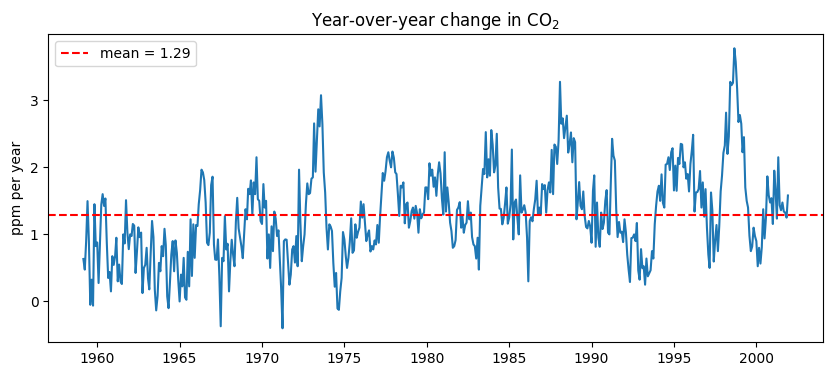

In [8]:
yoy = co2_m.diff(12)
print('Average annual increase, 1960s:', round(yoy['1960':'1969'].mean(), 2), 'ppm/year')
print('Average annual increase, 1990s:', round(yoy['1990':'1999'].mean(), 2), 'ppm/year')

plt.plot(yoy)
plt.axhline(yoy.mean(), color='r', ls='--', label=f'mean = {yoy.mean():.2f}')
plt.ylabel('ppm per year'); plt.title('Year-over-year change in CO$_2$')
plt.legend();

### 1.6 Seasonality

To see the seasonal pattern clearly we first remove the trend (here, with the 12-month rolling mean) and then group the result by calendar month.

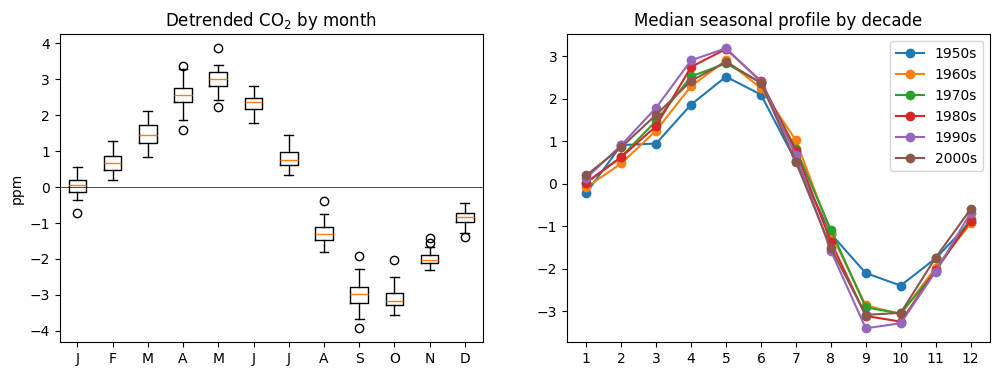

In [9]:
detrended = (co2_m - roll_mean).dropna()
month = detrended.index.month

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# Box plot by month: median, quartiles and outliers of each month
groups = [detrended[month == m].values for m in range(1, 13)]
ax[0].boxplot(groups)
ax[0].set_xticks(range(1, 13))
ax[0].set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_title('Detrended CO$_2$ by month'); ax[0].set_ylabel('ppm')

# Seasonal profile per decade: does the shape change?
for dec, grp in detrended.groupby((detrended.index.year // 10) * 10):
    ax[1].plot(range(1, 13), grp.groupby(grp.index.month).median(), marker='o', label=f'{dec}s')
ax[1].set_xticks(range(1, 13)); ax[1].set_title('Median seasonal profile by decade')
ax[1].legend();

> **Question:** in which month is CO$_2$ highest, and in which lowest? Can you explain it? (Hint: think about plants in the Northern Hemisphere.) Is the size of the seasonal swing constant across decades?

### 1.7 Decomposition

A **decomposition** splits the series into trend + seasonal + remainder. This is a descriptive tool, not a forecasting model. We use STL (*Seasonal-Trend decomposition using Loess*), which is robust to outliers.

Share of variance - trend: 0.990, seasonal: 0.0140, remainder: 0.00022


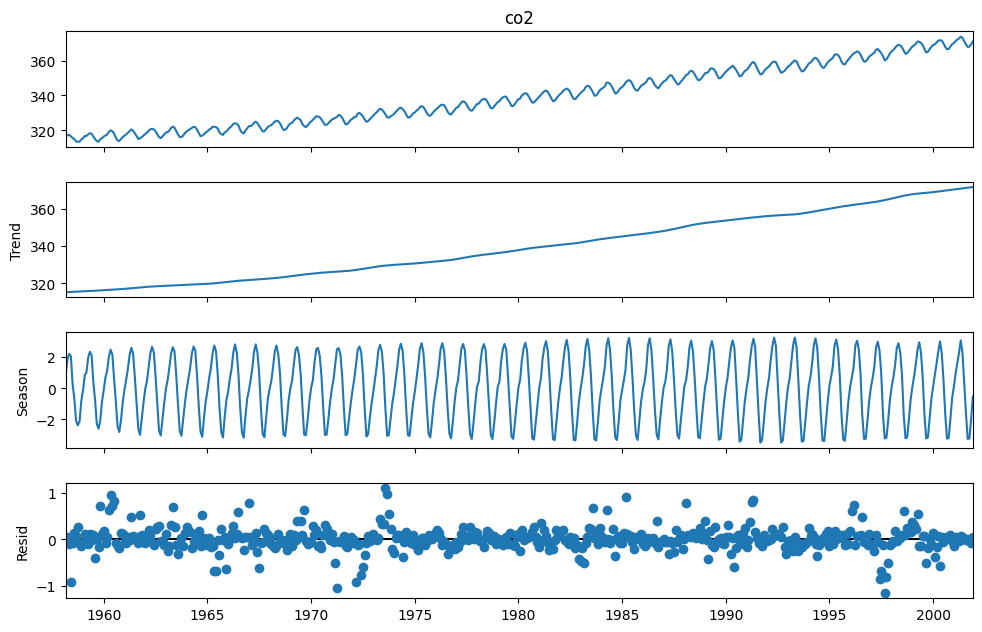

In [10]:
stl = STL(co2_m, period=12, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(10, 7)

var_total = co2_m.var()
print(f'Share of variance - trend: {stl.trend.var()/var_total:.3f}, '
      f'seasonal: {stl.seasonal.var()/var_total:.4f}, remainder: {stl.resid.var()/var_total:.5f}')

### 1.8 Autocorrelation

The **autocorrelation function (ACF)** measures the correlation between $x_t$ and $x_{t-h}$ for each lag $h$.

> **Question:** the ACF of the raw series decays very slowly. What does that tell you? Compare it with the ACF of the year-over-year change.

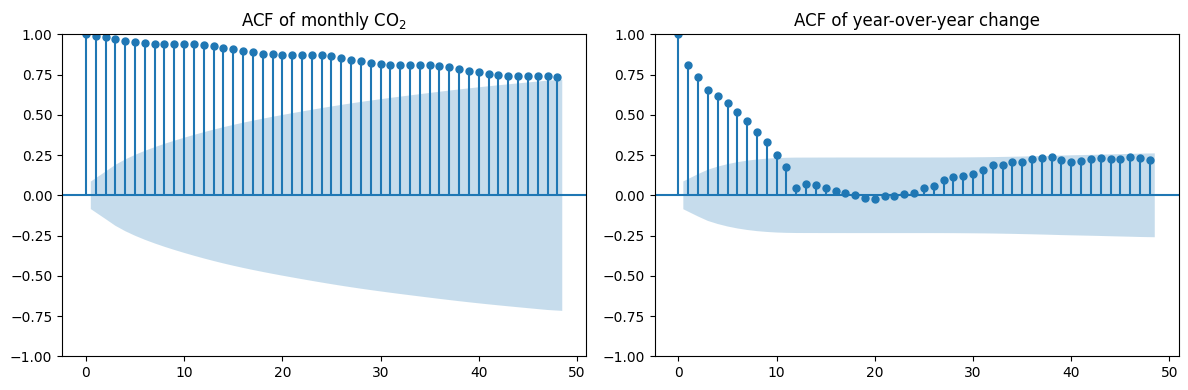

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(co2_m, lags=48, ax=ax[0], title='ACF of monthly CO$_2$')
plot_acf(yoy.dropna(), lags=48, ax=ax[1], title='ACF of year-over-year change')
plt.tight_layout();

### 1.9 Stationarity checks

Two common tests, with **opposite** null hypotheses:

* **ADF** (Augmented Dickey–Fuller): $H_0$ = the series has a unit root (non-stationary).
* **KPSS**: $H_0$ = the series is stationary.

We use them only as a diagnostic of what we see in the plots. Note that `statsmodels` reports KPSS p-values only between 0.01 and 0.10: a value of 0.010 means "0.01 or less", and 0.100 means "0.10 or more".

In [12]:
def stationarity_report(x, name):
    x = pd.Series(x).dropna()
    adf_p = adfuller(x, autolag='AIC')[1]
    kpss_p = kpss(x, regression='c', nlags='auto')[1]
    print(f'{name:<28s} ADF p = {adf_p:6.3f}   KPSS p = {kpss_p:6.3f}')

stationarity_report(co2_m, 'CO2 level')
stationarity_report(yoy, 'CO2 year-over-year change')
stationarity_report(stl.resid, 'CO2 STL remainder')

CO2 level                    ADF p =  0.999   KPSS p =  0.010
CO2 year-over-year change    ADF p =  0.000   KPSS p =  0.010
CO2 STL remainder            ADF p =  0.000   KPSS p =  0.100


**Summary of Part 1.** The CO$_2$ series is clean apart from a few missing weeks, has a strong and *accelerating* upward trend, a very regular seasonal cycle peaking in May, and a tiny remainder. The level is clearly non-stationary.

---
## **Part 2 - Sunspots**

The yearly mean number of sunspots, 1700–2008. Unlike CO$_2$, it has no trend, but it has a strong cycle and a very asymmetric distribution.

Observations: 309   Missing: 0   Frequency: YS-JAN


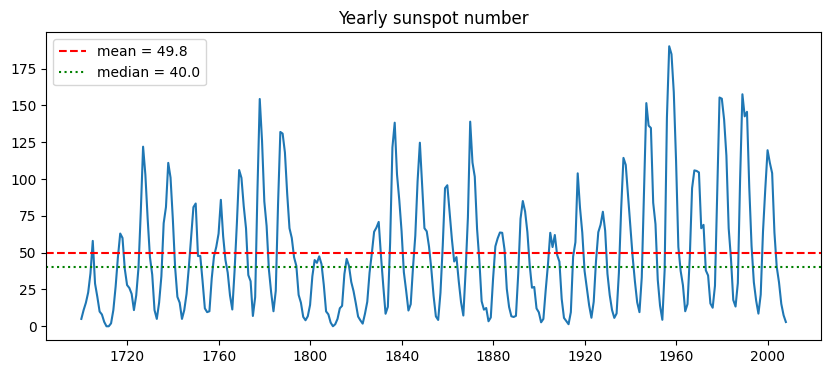

In [13]:
sun = sm.datasets.sunspots.load_pandas().data
sun.index = pd.to_datetime(sun['YEAR'].astype(int).astype(str))   # year -> date
sun = sun['SUNACTIVITY']

print('Observations:', len(sun), '  Missing:', sun.isna().sum(), '  Frequency:', pd.infer_freq(sun.index))

plt.plot(sun)
plt.axhline(sun.mean(), color='r', ls='--', label=f'mean = {sun.mean():.1f}')
plt.axhline(sun.median(), color='g', ls=':', label=f'median = {sun.median():.1f}')
plt.title('Yearly sunspot number'); plt.legend();

### 2.1 Distribution: mean vs. median

When a distribution is skewed, the mean and the median tell different stories.

count    309.0
mean      49.8
std       40.5
min        0.0
25%       16.0
50%       40.0
75%       69.8
max      190.2
Name: SUNACTIVITY, dtype: float64

Mean   = 49.8
Median = 40.0
Skewness = 0.99   Excess kurtosis = 0.44
Share of years with zero sunspots: 1.0%


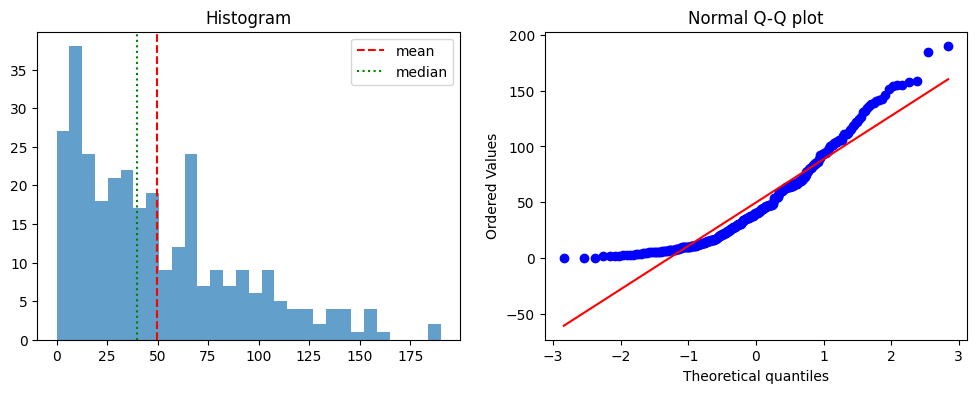

In [14]:
print(sun.describe().round(1))
print()
print(f'Mean   = {sun.mean():.1f}')
print(f'Median = {sun.median():.1f}')
print(f'Skewness = {sun.skew():.2f}   Excess kurtosis = {sun.kurt():.2f}')
print(f'Share of years with zero sunspots: {(sun == 0).mean()*100:.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(sun, bins=30, color='tab:blue', alpha=0.7)
ax[0].axvline(sun.mean(), color='r', ls='--', label='mean')
ax[0].axvline(sun.median(), color='g', ls=':', label='median')
ax[0].set_title('Histogram'); ax[0].legend()
stats.probplot(sun, dist='norm', plot=ax[1])
ax[1].set_title('Normal Q-Q plot');

> **Question:** why is the mean larger than the median? Which of the two would you report as the "typical" year?

### 2.2 Transformations

Skewed, positive series are often easier to analyse after a **variance-stabilising** transformation. The square root is the classical choice for counts such as sunspots (it handles zeros, unlike the logarithm).

Skewness  original: 0.99   sqrt: 0.18


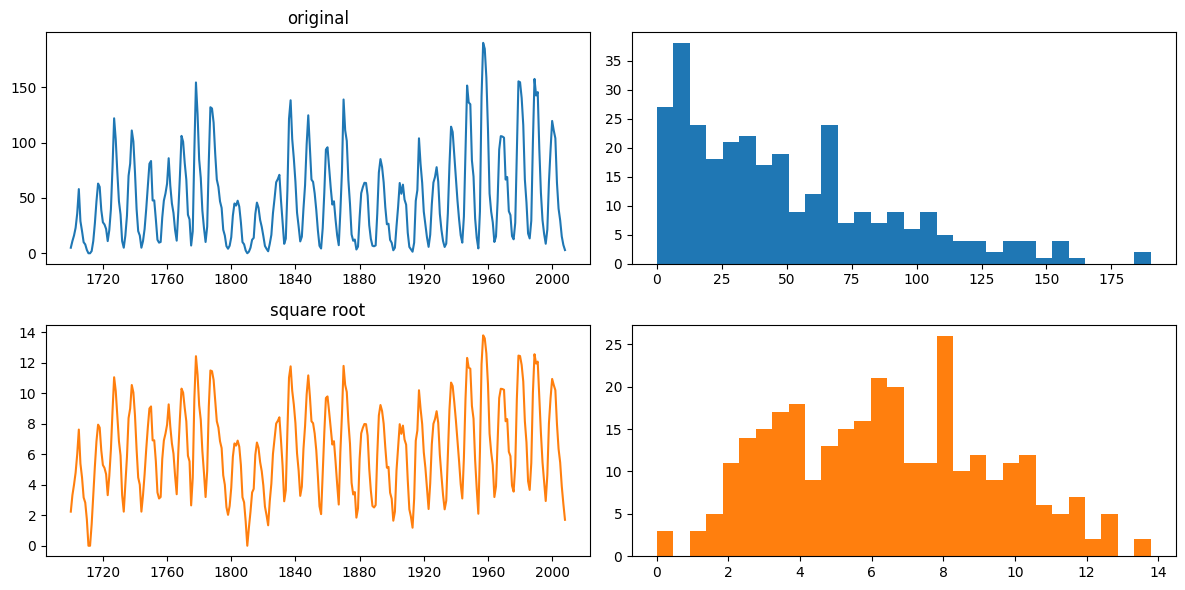

In [15]:
sun_sqrt = np.sqrt(sun)

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
ax[0, 0].plot(sun);       ax[0, 0].set_title('original')
ax[0, 1].hist(sun, bins=30)
ax[1, 0].plot(sun_sqrt, color='tab:orange'); ax[1, 0].set_title('square root')
ax[1, 1].hist(sun_sqrt, bins=30, color='tab:orange')
plt.tight_layout()

print(f'Skewness  original: {sun.skew():.2f}   sqrt: {sun_sqrt.skew():.2f}')

### 2.3 Outliers or extremes?

A classical rule (Tukey's fences, the rule behind box plots) flags values above $Q_3 + 1.5\,\mathrm{IQR}$ or below $Q_1 - 1.5\,\mathrm{IQR}$, where IQR $= Q_3 - Q_1$ is the interquartile range.

Q1 = 16.0, Q3 = 69.8, IQR = 53.8  ->  flag values above 150.5 or below -64.7
YEAR
1778-01-01    154.4
1947-01-01    151.6
1957-01-01    190.2
1958-01-01    184.8
1959-01-01    159.0
1979-01-01    155.4
1980-01-01    154.6
1989-01-01    157.6


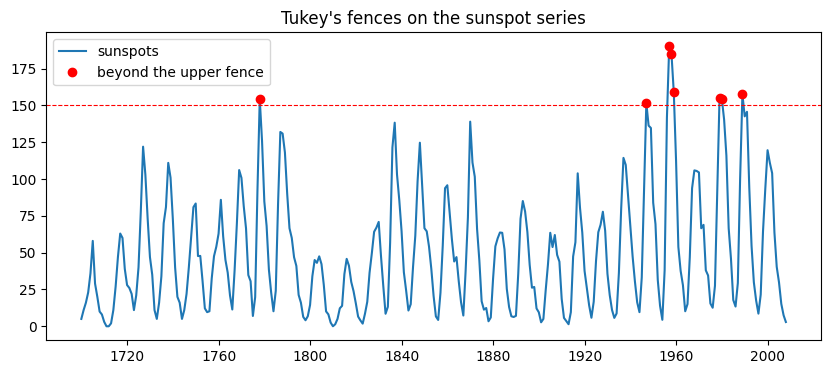

In [16]:
q1, q3 = sun.quantile([0.25, 0.75])
iqr = q3 - q1
upper, lower = q3 + 1.5 * iqr, q1 - 1.5 * iqr
flags = (sun > upper) | (sun < lower)
print(f'Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}  ->  flag values above {upper:.1f} or below {lower:.1f}')
print(sun[flags].round(1).to_string())

plt.plot(sun, label='sunspots')
plt.plot(sun[flags], 'ro', label='beyond the upper fence')
plt.axhline(upper, color='r', ls='--', lw=0.8)
plt.legend(); plt.title("Tukey's fences on the sunspot series");

> **Question:** are the flagged years errors, or genuine solar maxima (look at 1957-1958)? An outlier rule finds *unusual* points, it does not tell you whether they are *wrong*. And notice that this rule ignores time: a value can be perfectly normal for its cycle and still be flagged.

### 2.4 Cycles: lag plots and ACF

A **lag plot** shows $x_t$ against $x_{t-h}$. A tight diagonal cloud means strong positive dependence; a curved or loop-shaped cloud hints at nonlinearity or cycles.

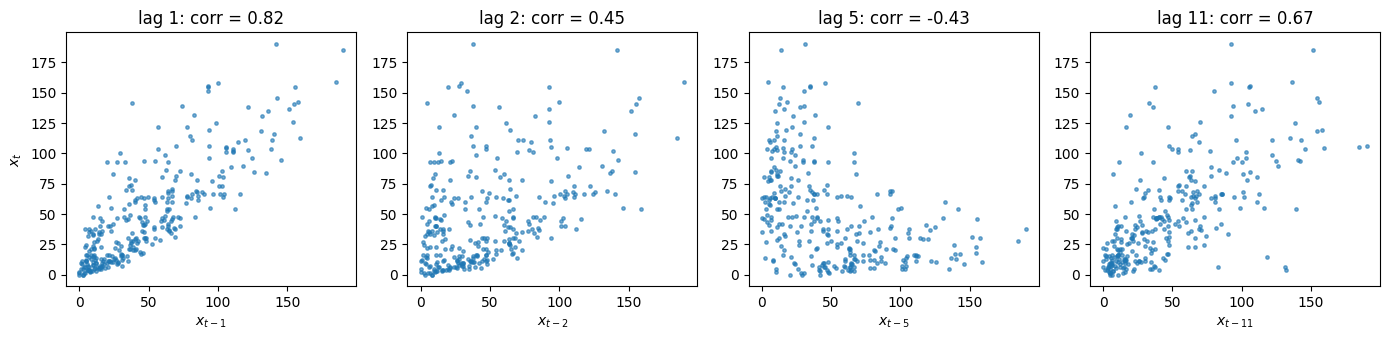

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for i, h in enumerate([1, 2, 5, 11]):
    ax[i].scatter(sun.shift(h), sun, s=6, alpha=0.6)
    r = sun.corr(sun.shift(h))
    ax[i].set_title(f'lag {h}: corr = {r:.2f}')
    ax[i].set_xlabel(f'$x_{{t-{h}}}$')
ax[0].set_ylabel('$x_t$')
plt.tight_layout();

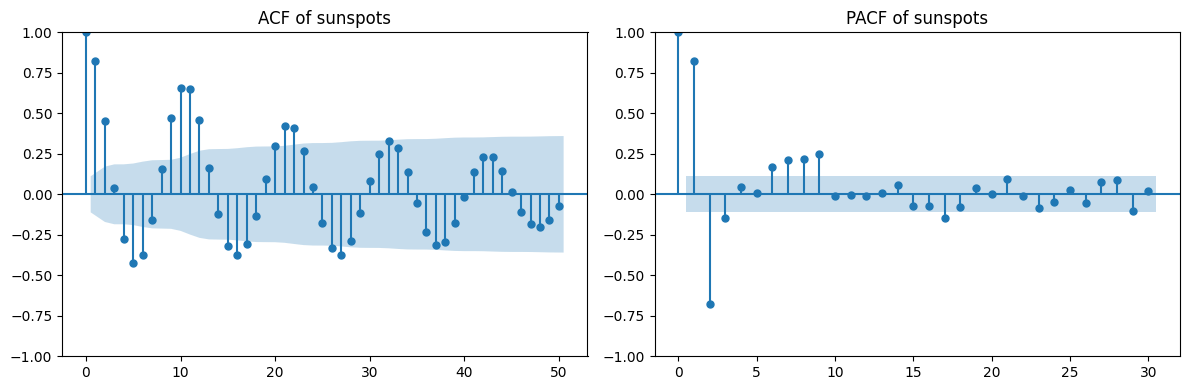

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(sun, lags=50, ax=ax[0], title='ACF of sunspots')
plot_pacf(sun, lags=30, ax=ax[1], method='ywm', title='PACF of sunspots')
plt.tight_layout();

The ACF is a damped wave. The distance between its peaks tells us the length of the cycle. We can also find it with a **periodogram**, which measures how much variance is carried by each frequency (we will study it properly in the spectral analysis session).

Dominant frequency: 0.0906 cycles/year  ->  period = 11.0 years


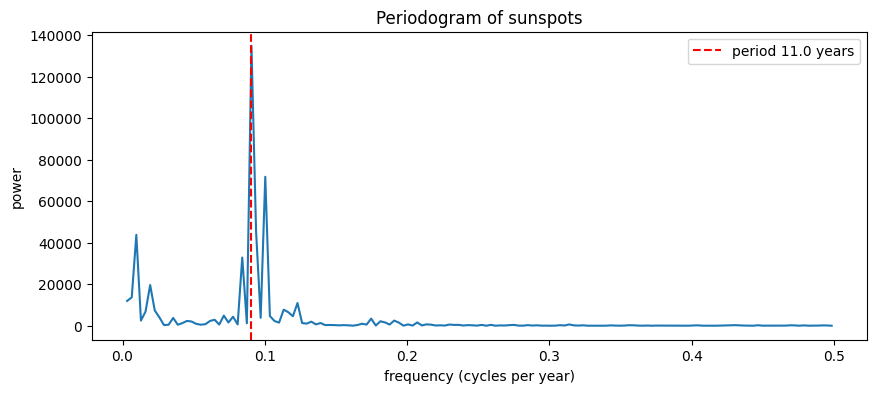

In [19]:
from scipy.signal import periodogram

freqs, power = periodogram(sun - sun.mean(), fs=1)       # fs = 1 observation per year
peak = freqs[np.argmax(power[1:]) + 1]
print(f'Dominant frequency: {peak:.4f} cycles/year  ->  period = {1/peak:.1f} years')

plt.plot(freqs[1:], power[1:])
plt.axvline(peak, color='r', ls='--', label=f'period {1/peak:.1f} years')
plt.xlabel('frequency (cycles per year)'); plt.ylabel('power')
plt.title('Periodogram of sunspots'); plt.legend();

### 2.5 Is the cycle stable?

Rolling statistics again: are the peaks getting higher or lower over the centuries?

Sunspots                     ADF p =  0.053   KPSS p =  0.016


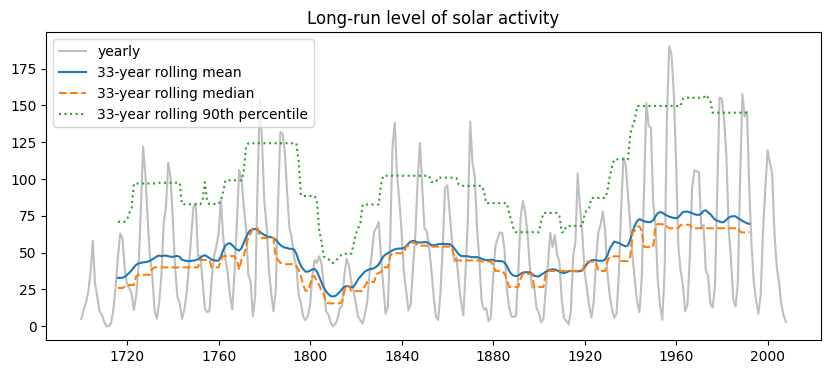

In [20]:
win = 33                                     # about three solar cycles
plt.plot(sun, color='0.75', label='yearly')
plt.plot(sun.rolling(win, center=True).mean(), label=f'{win}-year rolling mean')
plt.plot(sun.rolling(win, center=True).median(), '--', label=f'{win}-year rolling median')
plt.plot(sun.rolling(win, center=True).quantile(0.9), ':', label=f'{win}-year rolling 90th percentile')
plt.legend(); plt.title('Long-run level of solar activity');

stationarity_report(sun, 'Sunspots')

**Summary of Part 2.** Sunspots have no trend but a strong cycle of about 11 years, a right-skewed distribution (mean > median), a long-run modulation of the peak heights, and an asymmetric shape (fast rise, slow decline) that a lag plot reveals.

---
## **Part 3 - Two series together: SOI and fish Recruitment**

From `astsa`: the **Southern Oscillation Index** (SOI, related to sea-surface temperature in the Pacific; El Niño events give negative values) and **Recruitment**, an index of the number of new fish, monthly from 1950 to 1987. The question is: *do these two series move together, and with what delay?*

              SOI    Rec
1950-01-01  0.377  68.63
1950-02-01  0.246  68.63
1950-03-01  0.311  68.63
1950-04-01  0.104  68.63
1950-05-01 -0.016  68.63
          SOI     Rec
count  453.00  453.00
mean     0.08   62.26
std      0.38   27.98
min     -1.00    1.72
25%     -0.18   39.62
50%      0.12   68.63
75%      0.37   86.85
max      1.00  100.00


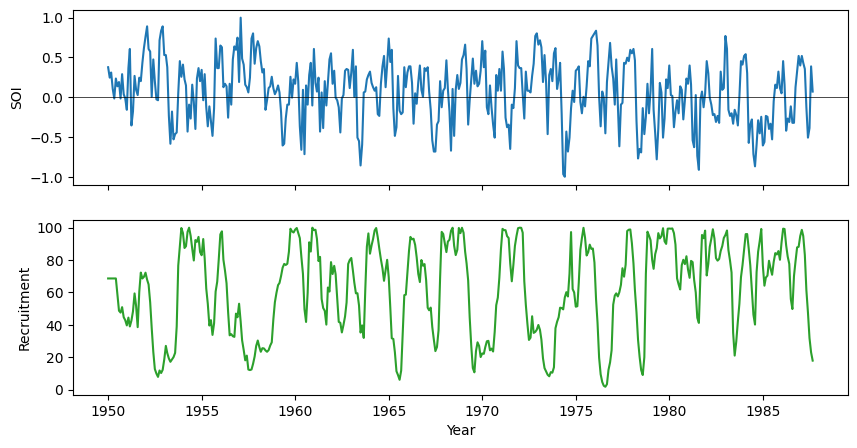

In [21]:
soi = astsa.load_soi()
rec = astsa.load_rec()

# Build a monthly date index from the decimal 'Time' column
idx = pd.date_range('1950-01-01', periods=len(soi), freq='MS')
df = pd.DataFrame({'SOI': soi['Value'].values, 'Rec': rec['Value'].values}, index=idx)
print(df.head())
print(df.describe().round(2))

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(df['SOI']); ax[0].set_ylabel('SOI'); ax[0].axhline(0, color='k', lw=0.5)
ax[1].plot(df['Rec'], color='tab:green'); ax[1].set_ylabel('Recruitment')
ax[1].set_xlabel('Year');

### 3.1 Seasonality of each series

        1      2      3      4      5      6      7      8      9      10  \
SOI   0.36   0.42   0.30  -0.15  -0.30  -0.17  -0.18  -0.04  -0.02   0.20   
Rec  77.51  77.03  72.92  69.41  63.54  56.44  45.30  40.00  46.41  71.54   

        11     12  
SOI   0.33   0.33  
Rec  77.48  80.17  


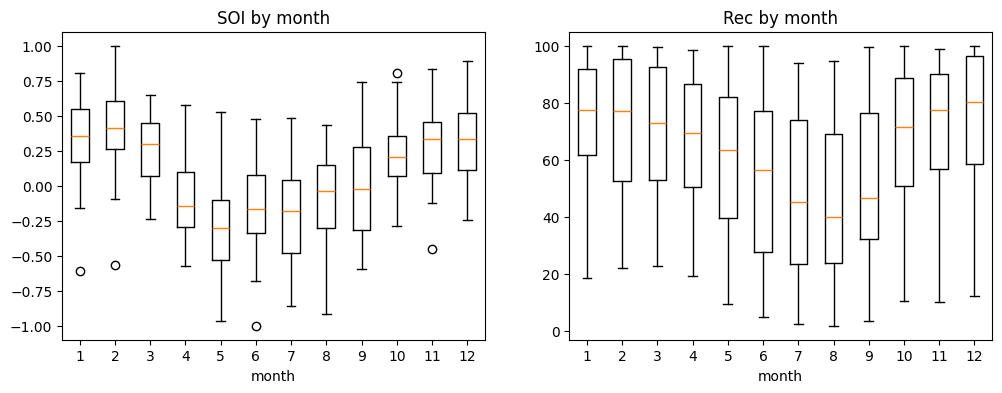

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, ['SOI', 'Rec']):
    a.boxplot([df.loc[df.index.month == m, col].values for m in range(1, 13)])
    a.set_xticks(range(1, 13))
    a.set_title(f'{col} by month'); a.set_xlabel('month')
print(df.groupby(df.index.month).median().round(2).T)

### 3.2 Contemporaneous correlation

We start with the simplest question: are the two series correlated *in the same month*? We compute both the usual **Pearson** correlation (linear) and the **Spearman** rank correlation (any monotonic relationship, robust to outliers).

Pearson  correlation: 0.025
Spearman correlation: 0.032


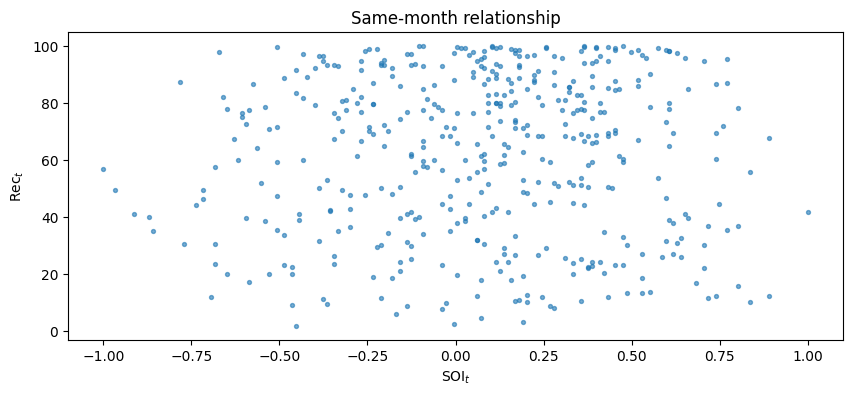

In [23]:
print('Pearson  correlation:', round(df['SOI'].corr(df['Rec'], method='pearson'), 3))
print('Spearman correlation:', round(df['SOI'].corr(df['Rec'], method='spearman'), 3))

plt.scatter(df['SOI'], df['Rec'], s=8, alpha=0.6)
plt.xlabel('SOI$_t$'); plt.ylabel('Rec$_t$'); plt.title('Same-month relationship');

### 3.3 Lagged relationship: the cross-correlation function

The **cross-correlation function (CCF)** computes $\mathrm{corr}(\text{Rec}_t, \text{SOI}_{t-h})$ for many lags $h$. A peak at a positive $h$ means that SOI **leads** Recruitment by $h$ months.

Strongest correlation at lag 6: -0.602


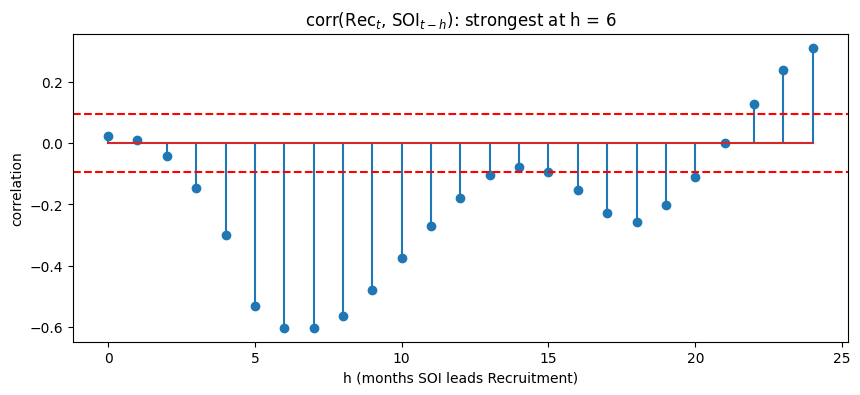

In [24]:
max_lag = 24
lags = np.arange(0, max_lag + 1)
cc = [df['Rec'].corr(df['SOI'].shift(h)) for h in lags]     # corr(Rec_t, SOI_{t-h})
best = lags[np.argmax(np.abs(cc))]
band = 2 / np.sqrt(len(df))

plt.stem(lags, cc)
plt.axhline(band, color='r', ls='--'); plt.axhline(-band, color='r', ls='--')
plt.xlabel('h (months SOI leads Recruitment)'); plt.ylabel('correlation')
plt.title(f'corr(Rec$_t$, SOI$_{{t-h}}$): strongest at h = {best}')
print(f'Strongest correlation at lag {best}: {cc[best]:.3f}')

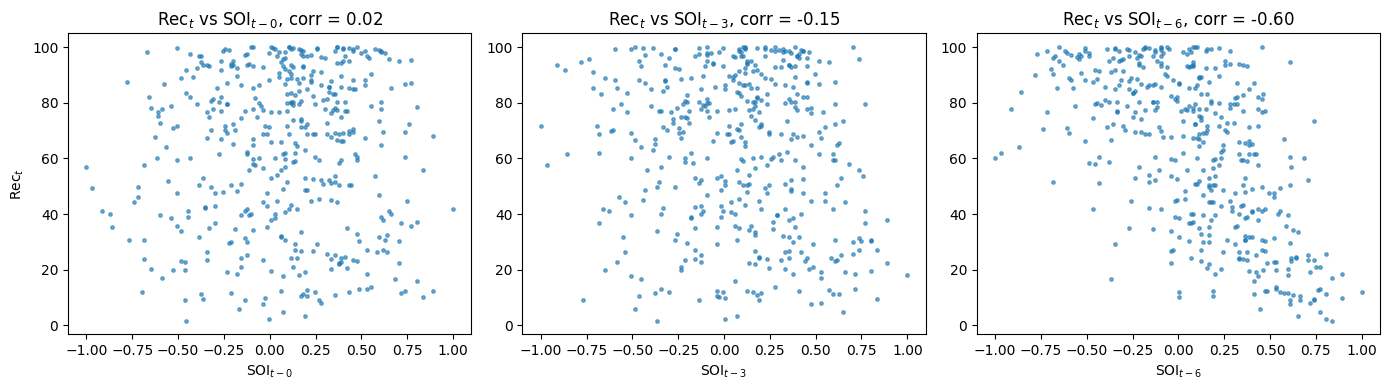

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, h in zip(ax, [0, 3, best]):
    a.scatter(df['SOI'].shift(h), df['Rec'], s=6, alpha=0.6)
    a.set_title(f'Rec$_t$ vs SOI$_{{t-{h}}}$, corr = {df["Rec"].corr(df["SOI"].shift(h)):.2f}')
    a.set_xlabel(f'SOI$_{{t-{h}}}$')
ax[0].set_ylabel('Rec$_t$')
plt.tight_layout();

> **Question:** look at the scatter plot at the best lag. Is the relationship a straight line, or does Recruitment react differently to negative and positive SOI values?

### 3.4 Does the relationship change over time?

A **rolling correlation** checks whether the link between the two series is stable.

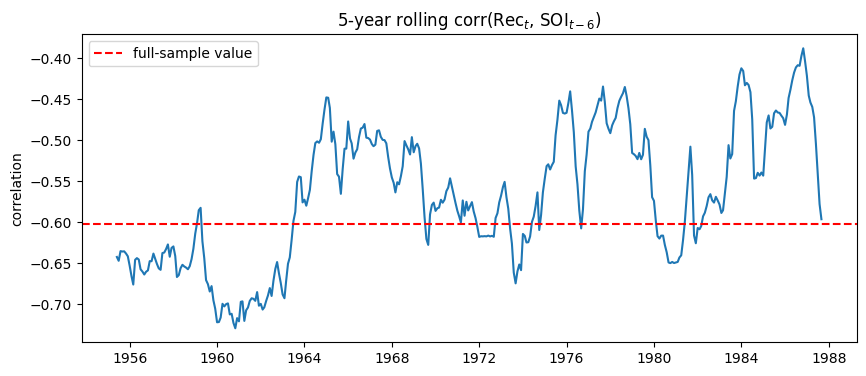

In [26]:
rc = df['Rec'].rolling(60).corr(df['SOI'].shift(best))      # 5-year window
plt.plot(rc)
plt.axhline(cc[best], color='r', ls='--', label='full-sample value')
plt.ylabel('correlation'); plt.title(f'5-year rolling corr(Rec$_t$, SOI$_{{t-{best}}}$)')
plt.legend();

### 3.5 A warning: spurious correlation between trending series

Two series that both trend will look strongly correlated even if they have nothing to do with each other. Let us see this with two *independent* random walks, and with real US macroeconomic data.

Correlation of the levels         : -0.636
Correlation of the changes (diff) : -0.039


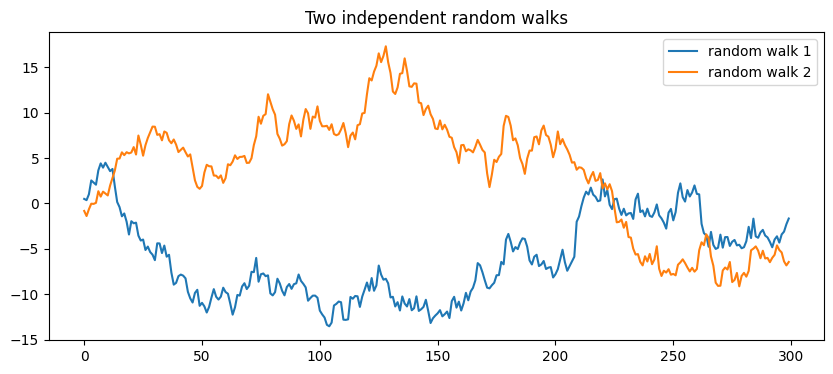

In [27]:
n = 300
rw1 = np.cumsum(np.random.randn(n))
rw2 = np.cumsum(np.random.randn(n))                 # generated independently of rw1!
print('Correlation of the levels         :', round(np.corrcoef(rw1, rw2)[0, 1], 3))
print('Correlation of the changes (diff) :', round(np.corrcoef(np.diff(rw1), np.diff(rw2))[0, 1], 3))

plt.plot(rw1, label='random walk 1'); plt.plot(rw2, label='random walk 2')
plt.legend(); plt.title('Two independent random walks');

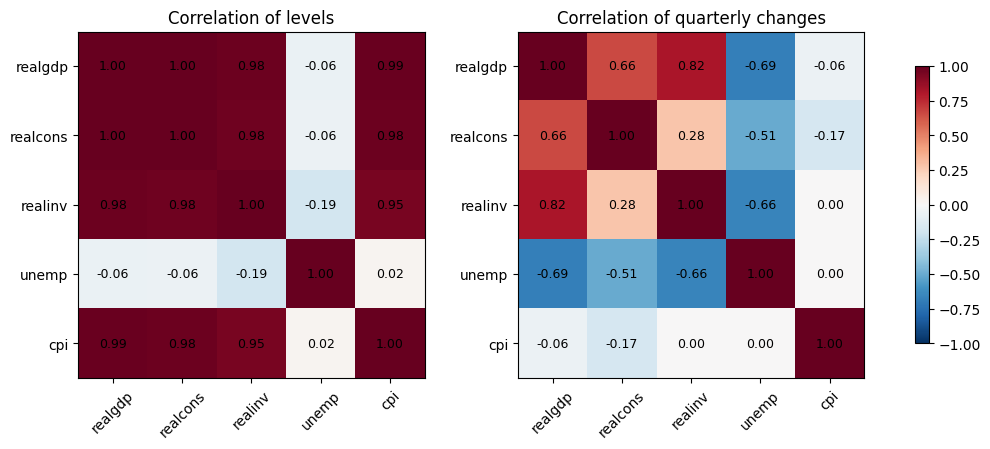

In [28]:
macro = sm.datasets.macrodata.load_pandas().data
macro.index = pd.period_range('1959Q1', periods=len(macro), freq='Q').to_timestamp()
cols = ['realgdp', 'realcons', 'realinv', 'unemp', 'cpi']

levels = macro[cols]
growth = np.log(macro[['realgdp', 'realcons', 'realinv', 'cpi']]).diff().mul(100)
growth['unemp'] = macro['unemp'].diff()                      # change in percentage points
growth = growth[cols].dropna()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, data, title in zip(ax, [levels, growth], ['levels', 'quarterly changes']):
    c = data.corr()
    im = a.imshow(c, vmin=-1, vmax=1, cmap='RdBu_r')
    a.set_xticks(range(len(cols))); a.set_xticklabels(cols, rotation=45)
    a.set_yticks(range(len(cols))); a.set_yticklabels(cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            a.text(j, i, f'{c.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
    a.set_title(f'Correlation of {title}')
fig.colorbar(im, ax=ax, shrink=0.8);

> **Question:** GDP and CPI (prices) have a correlation close to 1 in levels. Does that mean that inflation causes growth? What happens to the correlation once we look at changes? Which matrix would you trust?

---
## **Wrap-up: an EDA checklist for any time series**

1. Check the index: dates, frequency, duplicates, **missing values and gaps**.
2. **Plot** the series. Then plot it again, zoomed in.
3. Compare **mean and median**, globally and in sub-periods; look at the **distribution** (histogram, Q-Q plot, skewness).
4. Use **rolling** mean, median and standard deviation to see changes in level and spread.
5. Look for **seasonality**: box plots by month (or weekday), seasonal profiles, decomposition.
6. Measure **dependence**: lag plots, ACF and PACF.
7. Check **stationarity**, visually and with ADF / KPSS.
8. With several series: correlations (Pearson and Spearman), **cross-correlations at different lags**, rolling correlations, and always compare levels with **changes** to avoid spurious correlation.
9. Flag **outliers** with robust rules, then decide whether they are errors or real events.

### Try it yourself

* Repeat Part 1 with `astsa.load_jj()` (Johnson & Johnson quarterly earnings). What transformation makes its variance stable?
* Repeat Part 2 with the daily Dow Jones returns, `astsa.load_djia()`. Compare mean and median, look at the tails, and compare the ACF of the returns with the ACF of the *squared* returns.
* In Part 3, compute the CCF using the first differences of both series. Does the best lag change?